In [1]:
import numpy as np
x_l1 = np.array([0.39, 0.09, 0.10, 0.19, 0.21, 0.08, 0.17, 0.25, 0.15])
x_ul1 = np.array([0.24, 0.39, 0.19, 0.16, 0.22, 0.13, 0.22, 0.22])
x_l = np.array([0.39, 0.48, 0.58, 0.77, 0.98, 1.06, 1.23, 1.48, 1.63])
x_ul = np.array([0.24, 0.63, 0.82, 0.98, 1.20, 1.33, 1.55, 1.77])
# units are in mm, lets convert to m
x_l, x_ul = x_l*0.001, x_ul*0.001
l_br = 0.497
t_br = 0.001*1.88
b_br = 50.048*0.001
Weight = np.array([108.7, 207.2, 305.2, 402.7, 501, 598.6, 697.4, 795.2, 894])
weight = Weight*0.001

print("Youngs Modulus is loading", weight*9.8*(l_br**3)/(4*b_br*t_br**3*x_l))
print("Young Modulus while unloading", weight[:-1]*9.8*(l_br**3)/(4*b_br*t_br**3*x_ul))
print(weight)

y1 = weight*9.8*(l_br**3)/(4*b_br*t_br**3*x_l)
y2 = weight[:-1]*9.8*(l_br**3)/(4*b_br*t_br**3*x_ul)

Youngs Modulus is loading [2.52080884e+11 3.90412298e+11 4.75917321e+11 4.73005162e+11
 4.62366783e+11 5.10746998e+11 5.12804476e+11 4.85947813e+11
 4.96049356e+11]
Young Modulus while unloading [4.09631436e+11 2.97456989e+11 3.36624447e+11 3.71646913e+11
 3.77599539e+11 4.07061517e+11 4.06935165e+11 4.06329245e+11]
[0.1087 0.2072 0.3052 0.4027 0.501  0.5986 0.6974 0.7952 0.894 ]


In [2]:
def EPR(M, d, L, B, W):
    y = ((M*9.8*L**3)/(4*B*W**3*d))*np.sqrt((0.0001/M)**2+9*(0.001/L)**2+
    (0.00001/B)**2+9*(0.00001/d)**2+(0.00002/B)**2)
    return y

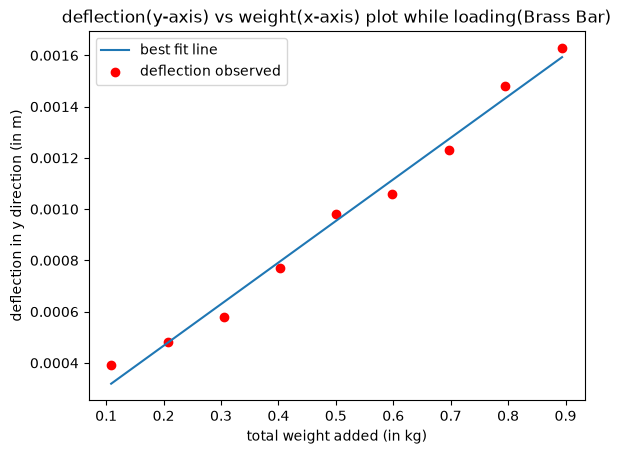

Sum Squared Errors 1.809548753744405e-08
Standard Error 5.084358020641635e-05
557369492413.9359
Absolute Error 167385111897.1361
Error Propagation [1.94521553e+10 2.45156494e+10 2.47848737e+10 1.86502028e+10
 1.44283991e+10 1.47822238e+10 1.28870131e+10 1.02802396e+10
 9.61093144e+09]


In [16]:
import matplotlib.pyplot as plt
w = np.linspace(0.1087 ,0.894, 200)
m,c = np.polyfit(weight,x_l,1)
plt.plot(w, m*w+c, label='best fit line')
plt.scatter(weight, x_l, color = 'red',label='deflection observed')
plt.xlabel('total weight added (in kg)')
plt.ylabel('deflection in y direction (in m)')
plt.title('deflection(y-axis) vs weight(x-axis) plot while loading(Brass Bar)')
plt.legend()
plt.show()

'''
sum squared Error
standard error
'''
sse = 0
y = m*weight+c
for i in range(0, len(x_l)):
    sse += (y[i]-x_l[i])**2
er = np.sqrt(sse/(len(x_l)-2))
print("Sum Squared Errors", sse)
print("Standard Error", er)
'''
determining Youngs Modulus from Slope
'''
Y = 9.8*l_br**3/(4*b_br*m*t_br**3)
print(Y)
'''
determining Absolute Error
'''
ab_er = 0
delta_Y = Y * (0.0001/weight + 3*(0.001/l_br) + 0.0002/b_br + 3*(0.0001)/t_br + 0.0001/x_l)
print("Absolute Error", np.mean(delta_Y))
#EPR
print('Error Propagation', EPR(weight, x_l, l_br, b_br, t_br))

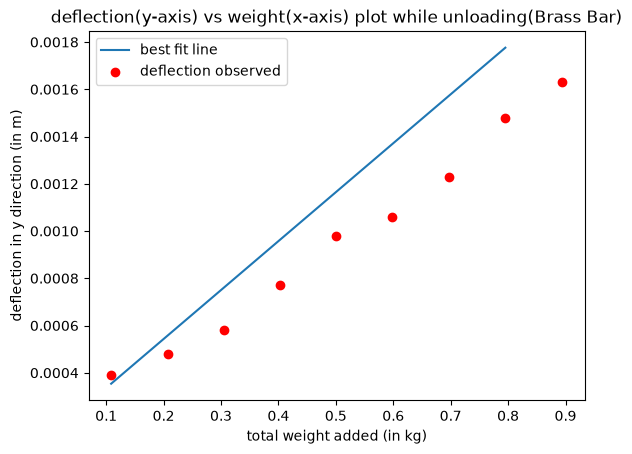

Sum Squared Errors 5.359659185240295e-07
Standard Error 0.0002767066312706421
436544275732.13025
Absolute Error 131099770324.72736
Error Propagation [5.12653077e+10 1.42793054e+10 1.24834211e+10 1.15975677e+10
 9.71301238e+09 9.50690599e+09 8.25251951e+09 7.31308121e+09]


In [13]:
import matplotlib.pyplot as plt
w = np.linspace(0.1087 ,0.7952, 200)
m,c = np.polyfit(weight[:-1],x_ul,1)
plt.plot(w, m*w+c, label='best fit line')
plt.scatter(weight, x_l, color = 'red', label='deflection observed')
plt.xlabel('total weight added (in kg)')
plt.ylabel('deflection in y direction (in m)')
plt.title('deflection(y-axis) vs weight(x-axis) plot while unloading(Brass Bar)')
plt.legend()
plt.show()
'''
sum squared Error
standard error
'''
sse = 0
y = m*weight+c
for i in range(0, len(x_l)):
    sse += (y[i]-x_l[i])**2
er = np.sqrt(sse/(len(x_l)-2))
print("Sum Squared Errors", sse)
print("Standard Error", er)
'''
determining Youngs Modulus from Slope
'''
Y = 9.8*l_br**3/(4*b_br*m*t_br**3)
print(Y)
'''
determining Absolute Error
'''
ab_er = 0
delta_Y = Y * (0.0001/weight + 3*(0.001/l_br) + 0.0002/b_br + 3*(0.0001)/t_br + 0.0001/x_l)
print("Absolute Error", np.mean(delta_Y))
print('Error Propagation', EPR(weight[:-1], x_ul, l_br, b_br, t_br))

In [5]:
import numpy as np
x_l1 = np.array([0.39, 0.09, 0.10, 0.19, 0.21, 0.08, 0.17, 0.25, 0.15])
x_ul1 = np.array([0.24, 0.39, 0.19, 0.16, 0.22, 0.13, 0.22, 0.22])
x_l2 = np.array([0.28, 0.50, 0.81, 1.01, 1.26, 1.5, 1.67, 1.93, 2.18])
x_ul2 = np.array([0.27, 0.54, 0.74, 1.03, 1.15, 1.33, 1.65, 1.83])
# units are in mm, lets convert to m
x_l2, x_ul2 = x_l2*0.001, x_ul2*0.001
l_br2 = 0.497
t_br2 = 0.001*5.53
b_br2 = 51*0.001
Weight2 = np.array([108.7, 207.3, 305.1, 403.3, 502.1, 599.7, 698.1, 795.9, 893.8])
weight2 = Weight2*0.001

print("Youngs Modulus is loading", weight2*9.8*(l_br2**3)/(4*b_br2*t_br2**3*x_l2))
print("Young Modulus while unloading", weight2[:-1]*9.8*(l_br2**3)/(4*b_br2*t_br2**3*x_ul2))
print(weight2)

y1 = weight2*9.8*(l_br2**3)/(4*b_br2*t_br2**3*x_l2)
y2 = weight2[:-1]*9.8*(l_br2**3)/(4*b_br2*t_br2**3*x_ul2)


Youngs Modulus is loading [1.35382083e+10 1.44583581e+10 1.31355079e+10 1.39250425e+10
 1.38966256e+10 1.39422373e+10 1.45777617e+10 1.43810593e+10
 1.42979422e+10]
Young Modulus while unloading [1.40396235e+10 1.33873687e+10 1.43780559e+10 1.36546533e+10
 1.52258680e+10 1.57243278e+10 1.47544619e+10 1.51669095e+10]
[0.1087 0.2073 0.3051 0.4033 0.5021 0.5997 0.6981 0.7959 0.8938]


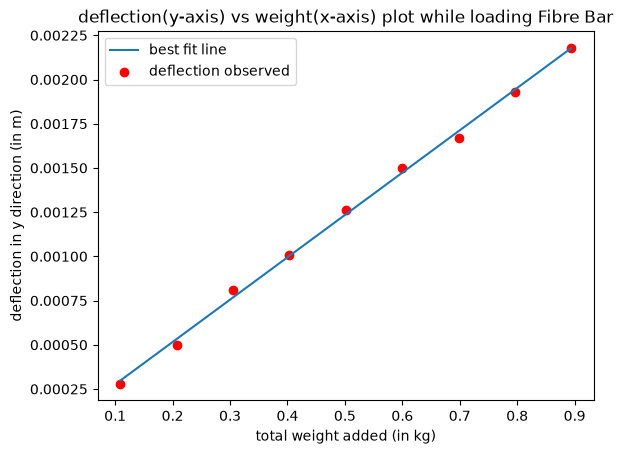

Sum Squared Errors 6.087366353758257e-09
Standard Error 2.948938393426706e-05
14564143312.206427
Absolute Error 2692422676.1211658
Error Propagation [1.45288797e+09 8.71931407e+08 4.92971550e+08 4.22127753e+08
 3.41405119e+08 2.91341375e+08 2.76346285e+08 2.39892779e+08
 2.14954081e+08]


In [14]:
import matplotlib.pyplot as plt
w2 = np.linspace(0.1087 ,0.8938, 200)
m2,c2 = np.polyfit(weight2,x_l2,1)
plt.plot(w2, m2*w2+c2, label='best fit line')
plt.scatter(weight2, x_l2, color = 'red', label='deflection observed')
plt.xlabel('total weight added (in kg)')
plt.ylabel('deflection in y direction (in m)')
plt.title('deflection(y-axis) vs weight(x-axis) plot while loading Fibre Bar')
plt.legend()
plt.show()
'''
sum squared Error
standard error
'''
sse = 0
y = m2*weight2+c2
for i in range(0, len(x_l2)):
    sse += (y[i]-x_l2[i])**2
er = np.sqrt(sse/(len(x_l2)-2))
print("Sum Squared Errors", sse)
print("Standard Error", er)
'''
determining Youngs Modulus from Slope
'''
Y = 9.8*l_br2**3/(4*b_br2*m2*t_br2**3)
print(Y)
'''
determining Absolute Error
'''
ab_er = 0
delta_Y = Y * (0.0001/weight + 3*(0.001/l_br2) + 0.0002/b_br2 + 3*(0.0001)/t_br2 + 0.0001/x_l2)
print("Absolute Error", np.mean(delta_Y))
print('Error Propagation', EPR(weight2, x_l2, l_br2, b_br2, t_br2))

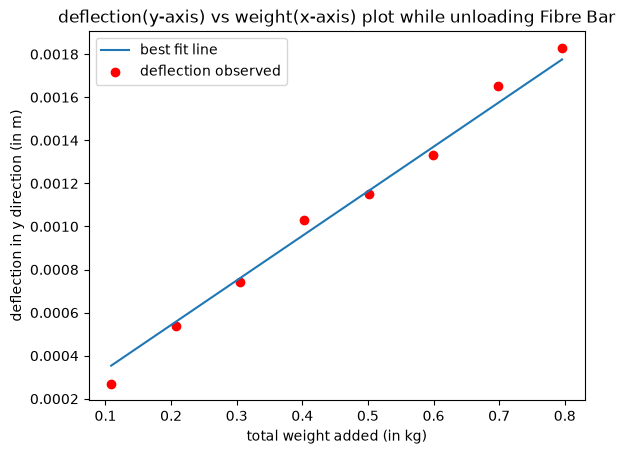

Sum Squared Errors 1.1320768376347868e-07
Standard Error 0.00012717124774069618
16857120608.502369
Absolute Error 3116317438.4862103
Error Propagation [1.56232394e+09 7.48170750e+08 5.89372456e+08 4.06217549e+08
 4.07756910e+08 3.67238547e+08 2.82742300e+08 2.65047505e+08]


In [15]:
import matplotlib.pyplot as plt
w2 = np.linspace(0.1087, 0.7959, 200)
m2,c2 = np.polyfit(weight2[:-1],x_ul,1)
plt.plot(w2, m2*w2+c2, label='best fit line')
plt.scatter(weight2[:-1], x_ul2, color = 'red', label='deflection observed')
plt.xlabel('total weight added (in kg)')
plt.ylabel('deflection in y direction (in m)')
plt.title('deflection(y-axis) vs weight(x-axis) plot while unloading Fibre Bar')
plt.legend()
plt.show()
'''
sum squared Error
standard error
'''
sse = 0
y = m2*weight2+c2
for i in range(0, len(x_l2)):
    sse += (y[i]-x_l2[i])**2
er = np.sqrt(sse/(len(x_l2)-2))
print("Sum Squared Errors", sse)
print("Standard Error", er)
'''
determining Youngs Modulus from Slope
'''
Y = 9.8*l_br2**3/(4*b_br2*m2*t_br2**3)
print(Y)
'''
determining Absolute Error
'''
ab_er = 0
delta_Y = Y * (0.0001/weight + 3*(0.001/l_br2) + 0.0002/b_br2 + 3*(0.0001)/t_br2 + 0.0001/x_l2)
print("Absolute Error", np.mean(delta_Y))
print('Error Propagation', EPR(weight2[:-1], x_ul2, l_br2, b_br2, t_br2))

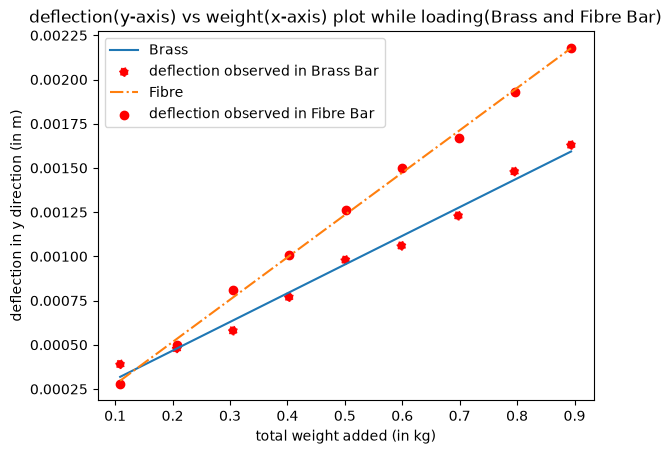

In [8]:
#Combined graph Loading
import matplotlib.pyplot as plt
w = np.linspace(0.1087 ,0.894, 200)
m,c = np.polyfit(weight,x_l,1)
plt.plot(w, m*w+c, label='Brass', ls='-')
plt.scatter(weight, x_l, color = 'red', label='deflection observed in Brass Bar', ls=':')
w2 = np.linspace(0.1087 ,0.8938, 200)
m2,c2 = np.polyfit(weight2,x_l2,1)
plt.plot(w2, m2*w2+c2, label='Fibre', ls='-.')
plt.scatter(weight2, x_l2, color = 'red',label='deflection observed in Fibre Bar')
plt.xlabel('total weight added (in kg)')
plt.ylabel('deflection in y direction (in m)')
plt.title('deflection(y-axis) vs weight(x-axis) plot while loading(Brass and Fibre Bar)')
plt.legend()
plt.show()

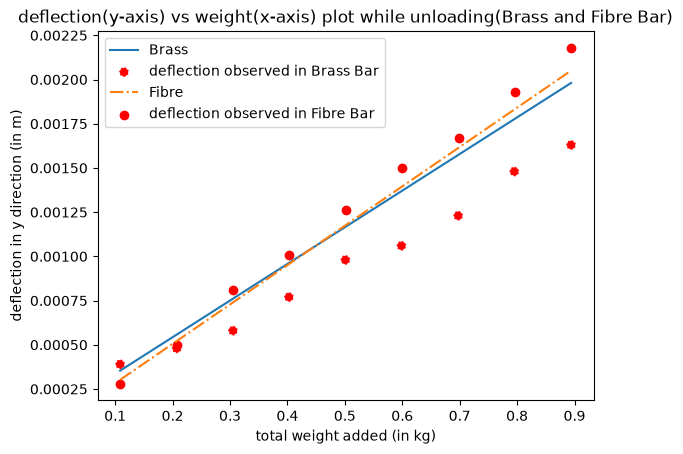

In [9]:
#Combined graph Loading
import matplotlib.pyplot as plt
w = np.linspace(0.1087 ,0.894, 200)
m,c = np.polyfit(weight[:-1],x_ul,1)
plt.plot(w, m*w+c, label='Brass', ls='-')
plt.scatter(weight, x_l, color = 'red', label='deflection observed in Brass Bar', ls=':')
w2 = np.linspace(0.1087 ,0.8938, 200)
m2,c2 = np.polyfit(weight2[:-1],x_ul2,1)
plt.plot(w2, m2*w2+c2, label='Fibre', ls='-.')
plt.scatter(weight2, x_l2, color = 'red', label='deflection observed in Fibre Bar')
plt.xlabel('total weight added (in kg)')
plt.ylabel('deflection in y direction (in m)')
plt.title('deflection(y-axis) vs weight(x-axis) plot while unloading(Brass and Fibre Bar)')
plt.legend()
plt.show()